# REINFORCE

Monte Carlo policy gradients reinforce sampled CartPole actions according to the discounted rewards that followed them. Each update uses six complete episodes.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Policy gradient

The actor samples while collecting trajectories. Within-batch normalisation centres the return weights. The unused value head receives no gradients.

In [2]:
import gymnasium as gym
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.distributions import Categorical
from gallery.cartpole import ActorCritic, cart_report, train_on_policy
from gallery.neural import seed_cpu


def train(seed):
    seed_cpu(seed)
    env = gym.make("CartPole-v1")
    net = ActorCritic()
    opt = torch.optim.Adam([*net.body.parameters(), *net.actor.parameters()], lr=0.003)
    history = []
    recent = []
    try:
        for batch in range(52):
            states = []
            actions = []
            returns = []
            for episode in range(6):
                state, _ = env.reset(seed=seed * 10000 + batch * 6 + episode)
                path = []
                while True:
                    obs = torch.tensor(state)
                    with torch.no_grad():
                        logits, _ = net(obs)
                        action = int(Categorical(logits=logits).sample())
                    states.append(obs)
                    actions.append(action)
                    state, r, done, cut, _ = env.step(action)
                    path.append(r)
                    if done or cut:
                        break
                recent.append(sum(path))
                g = 0.0
                discounted = []
                for r in reversed(path):
                    g = r + 0.99 * g
                    discounted.append(g)
                returns.extend(reversed(discounted))
            weight = torch.tensor(returns, dtype=torch.float32)
            weight = (weight - weight.mean()) / (weight.std() + 1e-6)
            logits, _ = net(torch.stack(states))
            loss = -(Categorical(logits=logits).log_prob(torch.tensor(actions)) * weight).mean()
            opt.zero_grad()
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            opt.step()
            history.append(np.mean(recent[-20:]))
    finally:
        env.close()
    return net, history

## Greedy evaluation

Twenty held-out starting states are shared across seeds and the random-policy baseline. CartPole pays one point per step.

Uniform-action mean return 29.8; SD 17.0


Seed 17: mean return 495.4, median 500.0, SD 20.8, 500-step fraction 95.0%


Seed 29: mean return 321.8, median 298.0, SD 153.4, 500-step fraction 30.0%


Seed 53: mean return 482.4, median 500.0, SD 33.8, 500-step fraction 60.0%
Across training seeds: mean 433.2, sample SD 96.7


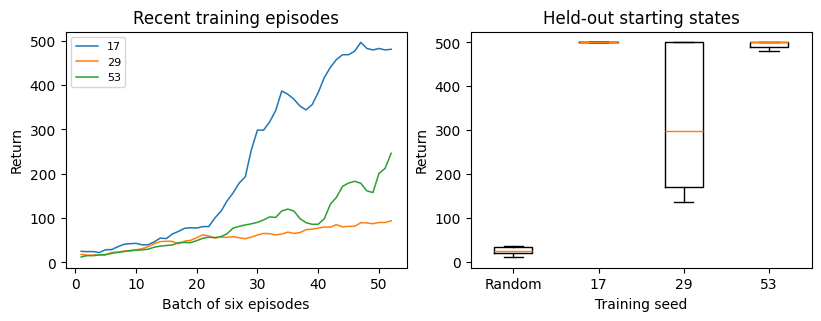

In [3]:
cart_report(train, "Batch of six episodes")
plt.show()

## Reading the result

The actor samples actions during training. Evaluation chooses its most likely action, so the two curves describe different policies.

## References

[Williams, Simple Statistical Gradient-Following Algorithms for Connectionist Reinforcement Learning (1992)](https://doi.org/10.1007/BF00992696)

[Farama Foundation, Gymnasium CartPole-v1](https://gymnasium.farama.org/environments/classic_control/cart_pole/)

[CartPole rollouts and evaluation](../../../gallery/cartpole.py)